In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
sys.path.append('../../Model_info')
import warnings
import seaborn as sns
# import cartopy
from cartopy import crs as ccrs, feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as plc
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import pandas as pd
import scipy.io   # reading matlab file v7.2
#import h5py       # reading matlab file v7.3

#from IPython.display import display
#  Suppress warnings issued by Cartopy when downloading data files
warnings.filterwarnings('ignore')

In [35]:
import Stdinput as ORCTM

CVCTM=ORCTM.Orctm_cvcm('ORCTM_cvcm','For model grid')
latp_grid = CVCTM.model_info_p('latp_grid')
lonp_grid = CVCTM.model_info_p('lonp_grid')
depto_grid = CVCTM.model_info_p('depto_grid')

'''
lonp_grid= CVCTM.Exclude_sponge(CVCTM.siw,CVCTM.sie,CVCTM.sjn,CVCTM.sjs,
                                 lonp_grid)
latp_grid = CVCTM.Exclude_sponge(CVCTM.siw,CVCTM.sie,CVCTM.sjn,CVCTM.sjs,
                                 latp_grid)
depto_grid = CVCTM.Exclude_sponge(CVCTM.siw,CVCTM.sie,CVCTM.sjn,CVCTM.sjs,
                                 depto_grid)
'''
ie_g = np.size(depto_grid,0)
je_g = np.size(depto_grid,1)

-------ORCTM Assignment-----
-------CVCTM Circulation Model-----
-------Based on CVTM configuration-----
       ie_g,je_g,ke
       End_date
       Start_date
       End_date
       Inv_date
       SDtime
       time_index
       dt
       Totalday
       Totalsecond
       LDTRUN
       isdiagnosis
       vars_code
       vars_name
 .     siw,sie,sjn,sjs (sponge layer)
-------ORCTM initialized-----


In [54]:
lat_station =[]
lon_station =[]
with open('M96_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13]))

with open('M97_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13]))

with open('M105_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13]))

with open('M106_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13]))   

with open('M107_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13]))        
        
with open('MSM22_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13]))    
        
with open('MSM23_new.txt','r') as CTDfile:
    for line in CTDfile:
        lat_station.append(float(line[27:33]))
        lon_station.append(float(line[27+12:33+13])) 

In [50]:
# CV Region range
lonW = -27
lonE = -13.5
latS = 9.5
latN = 19

cLat = (latN + latS) / 2
cLon = (lonW + lonE) / 2
res = '10m' # resolution :: “10m”, “50m”, and “110m”

# colormap clim
cmp_min = 0
cmp_max = 6
cmp_inv = 1
cmp_ticks = np.arange(cmp_min, cmp_max+cmp_inv, cmp_inv)
# quvier step
#arrow_step = 10
# matlab colormap
colormap = scipy.io.loadmat('/Users/josephhuang/Documents/colorbar/MPL_terrain_r.mat')
colors= colormap['MPL_terrain_r']
MPL_terrain_r = plc.ListedColormap(colors, name='MPL_terrain_r')

# Projection
projPC = ccrs.PlateCarree()
land_10m = cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                        edgecolor='black',
                                        facecolor='white')
lat_mooring=np.zeros(6,)
lon_mooring=np.zeros(6,)
# CVOO
lat_mooring[0] = 17.5998
lon_mooring[0] = -24.2500

lat_s  = [ 17.9900,16.8667,14.6767 ]
lon_s  = [ -16.0367,-24.9833,-17.4200 ]
 
lat_s  = [ 16.7550,17.9900,14.6767 ]
lon_s  = [ -22.9833,-16.0367,-17.4200 ]

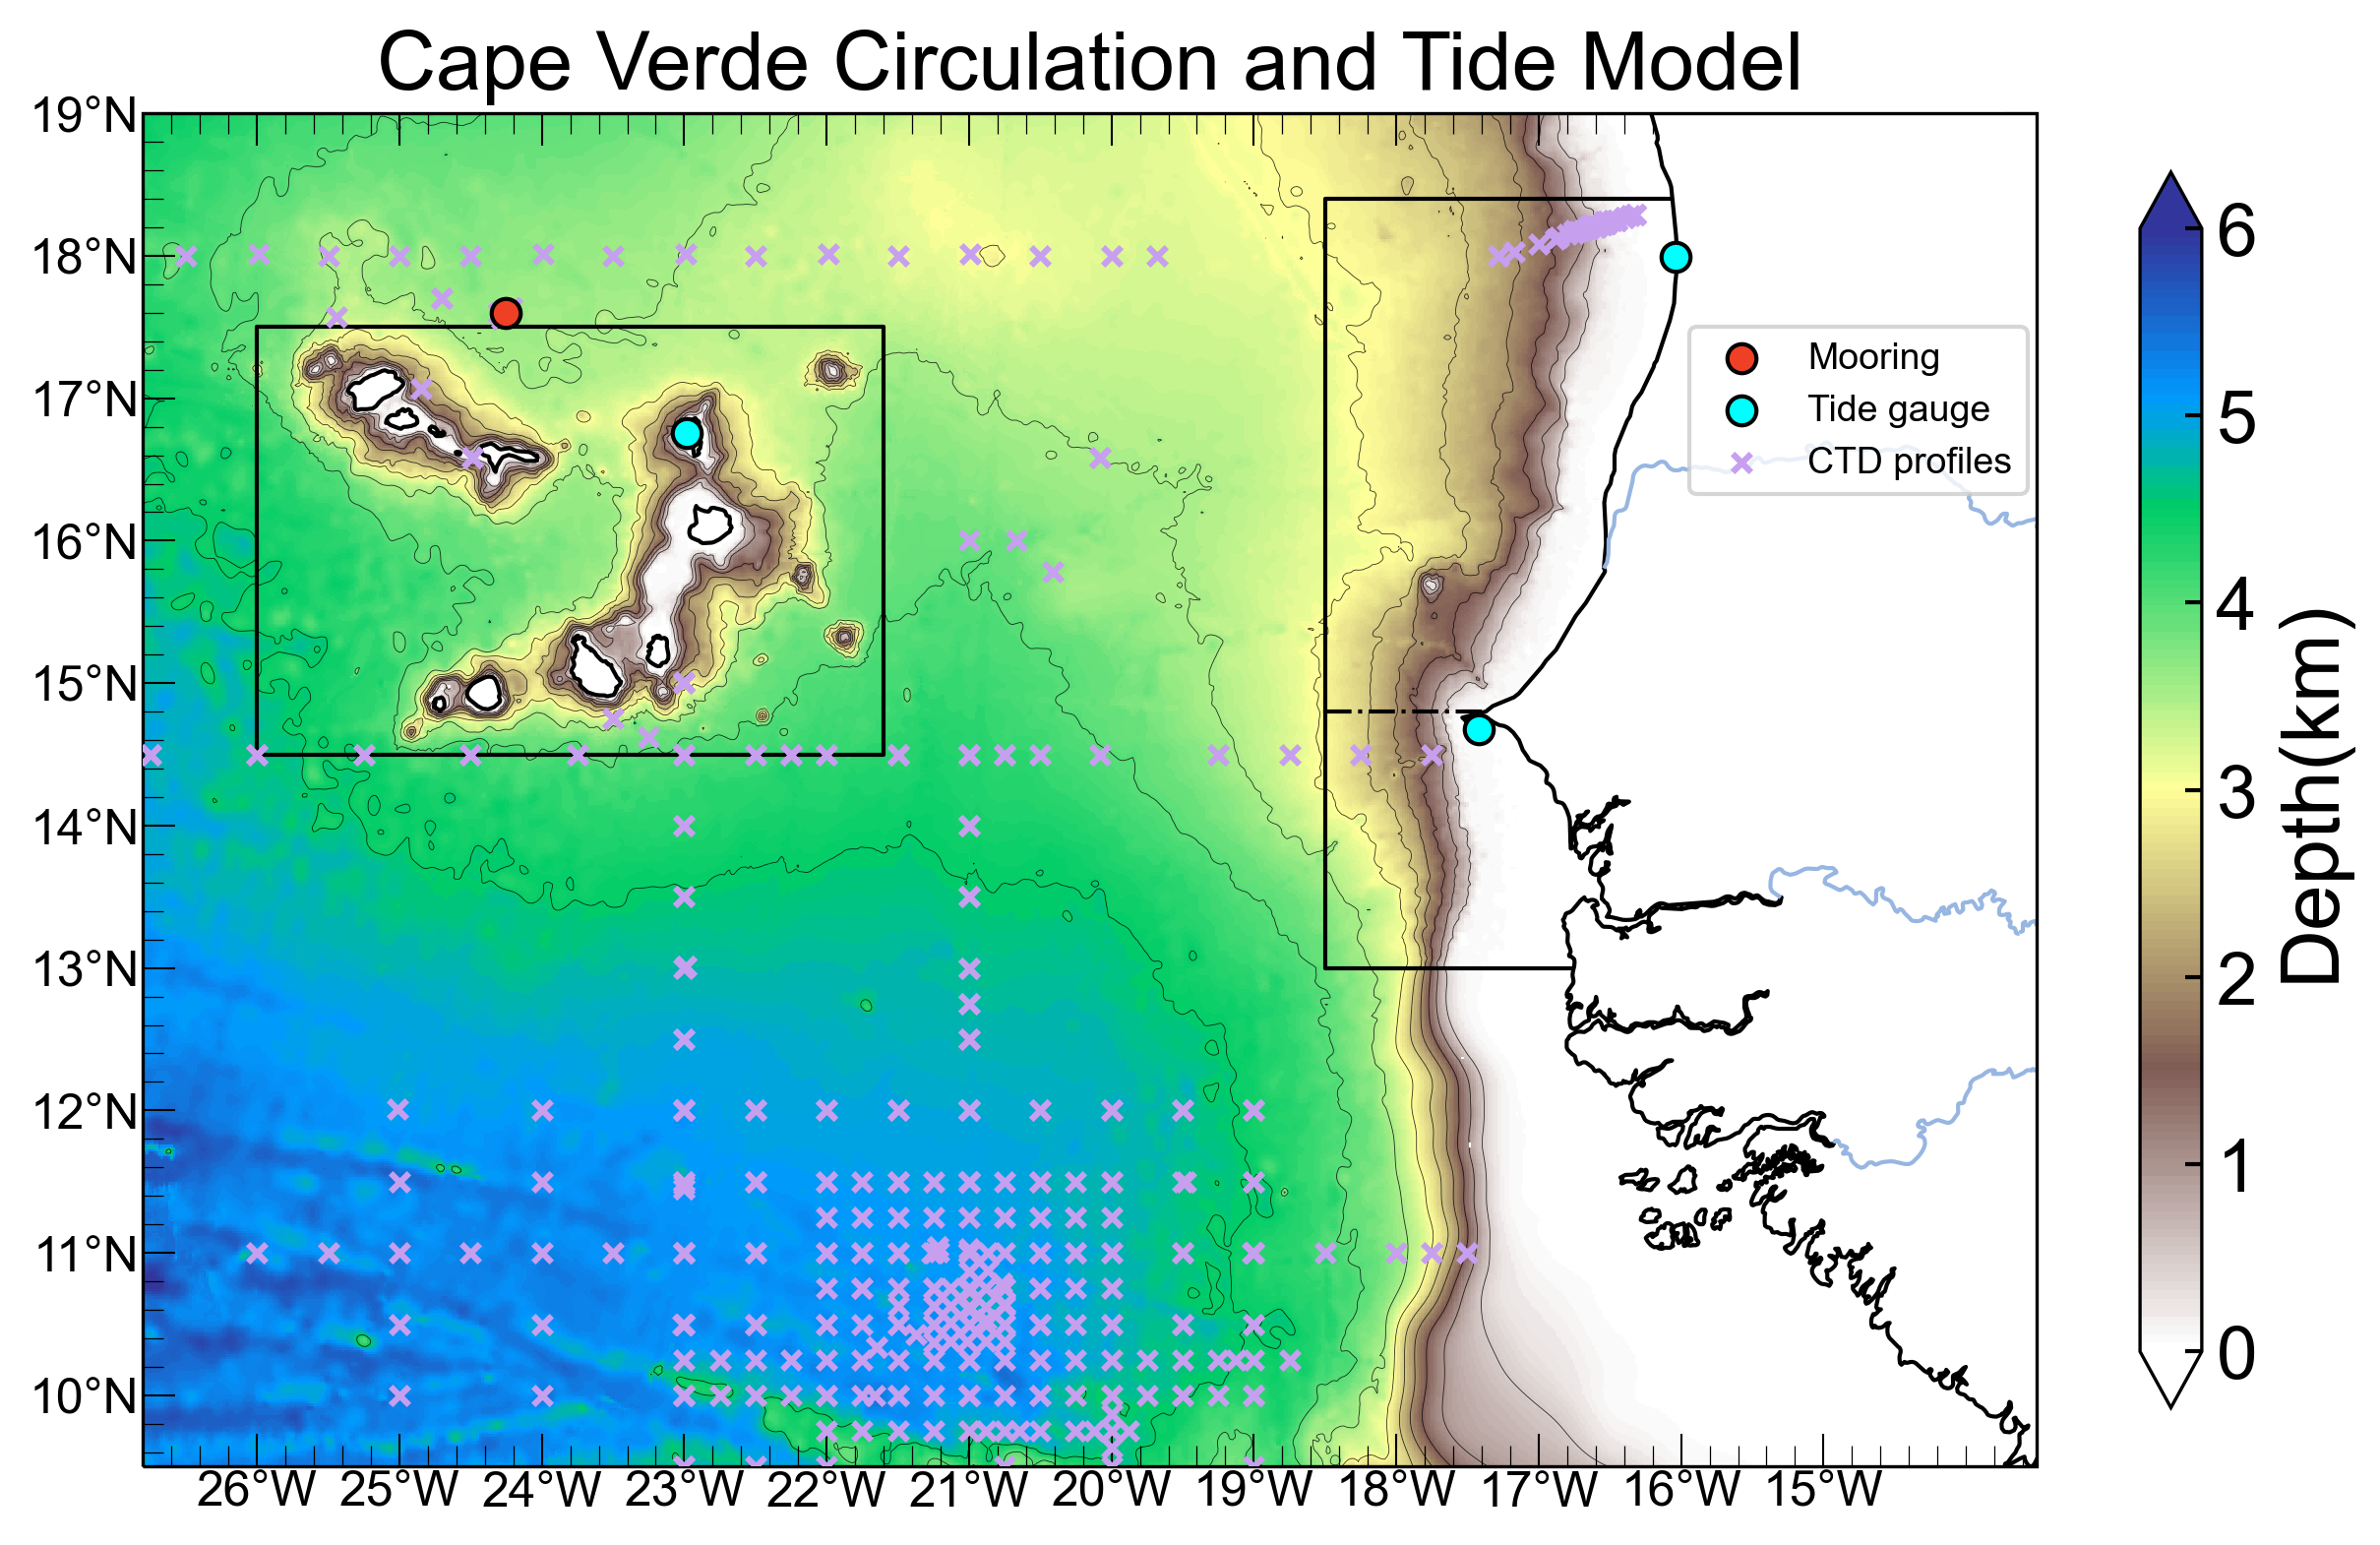

In [ ]:
fig = plt.figure(num='CVCTM_Figure1', figsize=(9, 6.5),facecolor='white',\
                edgecolor=None,dpi=300)
# Fontsize & Fontname
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 8

ax = plt.subplot(1, 1, 1, projection = projPC)
color_d = ax.pcolormesh(lonp_grid, latp_grid, depto_grid*1e-3,
                       cmap=MPL_terrain_r, vmin=cmp_min, vmax=cmp_max, transform=ccrs.PlateCarree())
line_d = ax.contour(lonp_grid, latp_grid, depto_grid*1e-3,
                colors='black',linewidths=0.2,zorder=1,alpha=0.8,
                transform=ccrs.PlateCarree(),levels=np.arange(0,5000,500)*1e-3)

# CVA area
LONLIMS = [-26,-21.8]
LATLIMS = [14.5,17.5]
box_lon = [LONLIMS[0],LONLIMS[0],LONLIMS[1],LONLIMS[1],LONLIMS[0]]
box_lat = [LATLIMS[0],LATLIMS[1],LATLIMS[1],LATLIMS[0],LATLIMS[0]]
ax.plot(box_lon,box_lat, linewidth=1, color='black',linestyle='-',transform=ccrs.PlateCarree(),zorder=1)

# MSS area
# NDA area
LONLIMS = [-18.5,-16]
LATLIMS = [14.8,18.4]
box_lon = [LONLIMS[0],LONLIMS[0],LONLIMS[1],LONLIMS[1]]
box_lat = [LATLIMS[0],LATLIMS[1],LATLIMS[1],LATLIMS[0]]
ax.plot(box_lon,box_lat, linewidth=1, color='black',linestyle='-',transform=ccrs.PlateCarree(),zorder=1)

ax.plot(LONLIMS,[LATLIMS[0],LATLIMS[0]], linewidth=1, color='black',linestyle='-.',transform=ccrs.PlateCarree(),zorder=1)
# SDA area
LONLIMS = [-18.5,-16.0]
LATLIMS = [13,14.8]
box_lon = [LONLIMS[0],LONLIMS[0],LONLIMS[1],LONLIMS[1]]
box_lat = [LATLIMS[1],LATLIMS[0],LATLIMS[0],LATLIMS[1]]
ax.plot(box_lon,box_lat, linewidth=1, color='black',linestyle='-',transform=ccrs.PlateCarree(),zorder=1)

# mooring
ax.scatter(lon_mooring[0],lat_mooring[0],s=50,\
                  marker='o',edgecolors='k',facecolors='#EF4026',transform=ccrs.PlateCarree(),alpha=1,zorder=4,\
                 label='Mooring')
ax.scatter(lon_s,lat_s,s=50,\
                  marker='o',edgecolors='k',facecolors='#00FFFF',transform=ccrs.PlateCarree(),alpha=1,zorder=3,\
                 label='Tide gauge')
ax.scatter(lon_station,lat_station,s=20,\
                  marker='x',edgecolors='k',facecolors='#C79FEF',transform=ccrs.PlateCarree(),alpha=1,zorder=3,\
                 label='CTD profiles')
ax.add_feature(land_10m,zorder=2)
#ax.add_feature(cfeature.LAND,zorder=2)
#ax.add_feature(cfeature.BORDERS, linestyle='--',linewidth=0.5, edgecolor='black',facecolor='k',zorder=2)
ax.add_feature(cfeature.LAKES, alpha=0.5,zorder=2)
ax.add_feature(cfeature.RIVERS,zorder=2)

gl = ax.gridlines(
        draw_labels=False, linewidth=1.5, color='gray', alpha=0.5, linestyle='--',\
        x_inline=False, y_inline=False,\
        xlocs = np.arange(-28,-14,1),ylocs=np.arange(10,21,1),\
    )
gl.xlines=False
gl.ylines=False

ax.set_xticks(np.arange(-28,-14,1), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(10,21,1), crs=ccrs.PlateCarree())

lon_formatter = LongitudeFormatter()
lat_formatter = LatitudeFormatter()

ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

ax.tick_params(axis='both',which='major',labelsize=12,\
               direction='in',length=8,width=0.5,pad=0.9,top=True,right=True)

ax.minorticks_on()
ax.tick_params(axis='both',which='minor',direction='in',length=5,width=0.3,top=True,right=True)
    
# colorbar
cbar1 = fig.colorbar(color_d,location='right',extend='both' \
      ,pad=0.05,ticks=cmp_ticks,fraction=0.03)
    
cbar1.ax.tick_params(labelsize=18,length=4, width=1,\
                        direction = 'in')

cbar1.set_label('Depth(km)', fontsize=20, fontfamily='Arial')

fig.legend(fontsize=9,loc=(0.71,0.68))

plt.title('Cape Verde Circulation and Tide Model', fontsize=20,\
                fontfamily='Arial',fontweight='regular')
                
ax.set_extent([-26.8, lonE, latS, latN], projPC)

plt.show()
fig.savefig('CVCTM_Figure1.tiff',dpi=300,bbox_inches='tight')